# Graph-latency benchmark — the summary figure

Builds one figure from the benchmark output. No re-running: a full sweep takes ~40 minutes,
this reads the CSVs it wrote.

The figure is sized for print at **5.5 inches wide** — the NeurIPS full text width — so it goes
into the paper with no rescaling, and every font size in it is a final size on the page.

**Panels 1–3** — synthetic sweeps, one dimension varied with the other two pinned, so each
fitted slope is a partial derivative: seconds of server work per extra grid point, mesh node,
or edge. Shared y axis so the three are comparable by eye, but each panel keeps its own tick
labels. The slope and R² are written into the panel; the legend just names the marks.

**Panel 4** — the shipped graphs, whole-render latency against edge count. Own axes: latency
is on a log scale, because the two members of a family (GraphCast multiscale/hierarchical,
SeaCast/Njord) differ by well under a second against a 22 s range and would otherwise land on
the same pixel. Green shades are the weather graphs and red shades the ocean ones — not blue,
which in the first three panels means "measured latency". Legend names come from
`DISPLAY_NAMES` in `bench_plots.py`, which maps the short name each graph was benchmarked
under to the mesh description the paper needs.

Every x axis factors out a single power of ten, printed at the right-hand end of the axis.

Regenerate the data with:

```
docker cp scripts/benchmark_graph_scaling.py xai-iml-26-backend-1:/tmp/bench.py
docker exec -w /usr/src/app xai-iml-26-backend-1 python /tmp/bench.py all \
    --generator random --totals-only --out /usr/data/bench_totals
```


In [6]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "scripts"))

import matplotlib.pyplot as plt
from bench_plots import load, summary_figure

plt.rcParams["figure.dpi"] = 110
d = load(pathlib.Path.cwd().parent / "backend" / "data" / "bench_totals")
d

BenchData(/workspace/gnn-view/backend/data/bench_totals: 21 graphs [4 real, 17 synthetic], 48 components)

  note: missing data for t for the g sweep; o for the g sweep; t for the g sweep; a for the g sweep; l for the g sweep; _ for the g sweep; s for the g sweep; q for the g sweep; _ for the g sweep; s for the g sweep; t for the m sweep; o for the m sweep; t for the m sweep; a for the m sweep; l for the m sweep; _ for the m sweep; s for the m sweep; q for the m sweep; _ for the m sweep; s for the m sweep; t for the e sweep; o for the e sweep; t for the e sweep; a for the e sweep; l for the e sweep; _ for the e sweep; s for the e sweep; q for the e sweep; _ for the e sweep; s for the e sweep


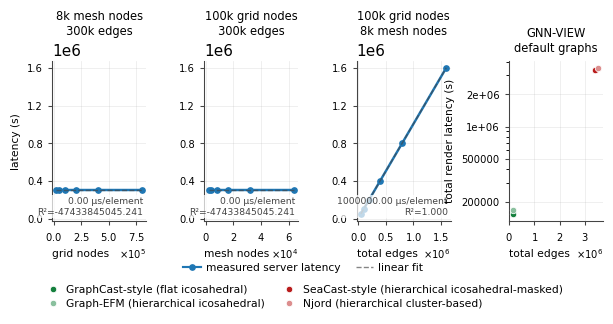

In [9]:
fig, (panels, ax_real) = summary_figure(d,ys=("total_seq_s"))
fig.savefig("summary.png", dpi=400, bbox_inches="tight")


## Variations

Everything is a keyword argument — see `help(summary_figure)` and the `AXES` dict in
`bench_plots.py` for the columns available on either axis.

  fit_real skipped: the real graphs occupy only 2 separated e group(s) (need 3). 4 distinct values, but they cluster -- a slope through them would be a two-point fit in disguise. Add graphs at more resolutions.


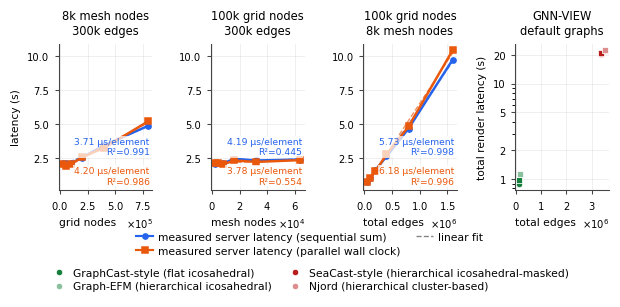

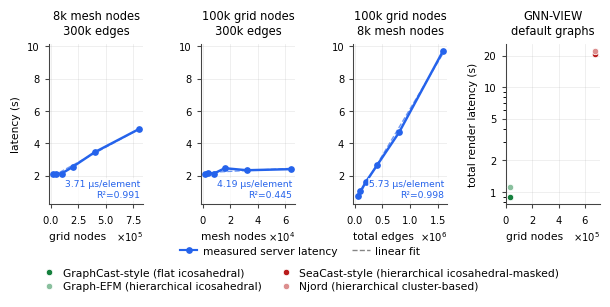

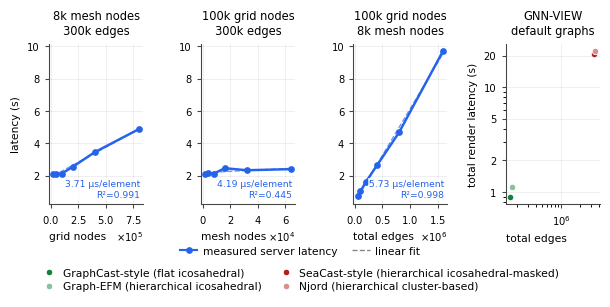

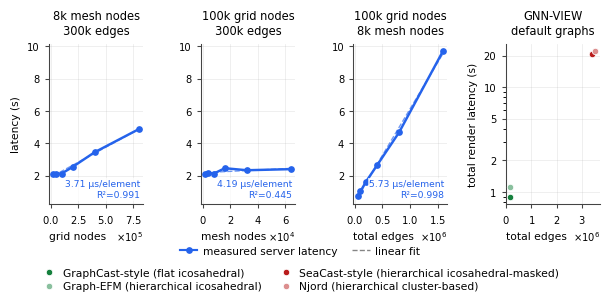

In [8]:
# Add the parallel wall clock back. Off by default: it sits almost on top of the sequential
# sum on a single-worker backend, and at 5.5 inches the overlap costs more than it tells you.
fig, _ = summary_figure(d, ys=("total_seq_s", "total_parallel_s"))

# Panel 4 against grid points instead of edges.
fig, _ = summary_figure(d, real_x="g")

# Panel 4 axis scaling: "logy" (default), "linear", or "loglog" once the shipped graphs span
# more than about two decades of edge count.
fig, _ = summary_figure(d, real_scale="loglog")

# Fit a line through the real graphs. Skipped automatically below 3 separated x clusters --
# with only the shipped graphs there are two, and a slope through two clusters is a two-point
# fit wearing a disguise. Add graphs at more resolutions and it will draw.
fig, _ = summary_figure(d, fit_real="linear")

# Names beside the points instead of in the legend, and a title on top of the figure.
